# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** 

Устройство: `cuda` (NVIDIA GeForce RTX 3050 Laptop GPU)

Модель: `cointegrated/rubert-tiny2`, [ссылка](https://huggingface.co/cointegrated/rubert-tiny2), лицензия MIT

Датасет: русскоязычные сплиты `WikiNEuRal` от Babelscape, [ссылка](https://huggingface.co/datasets/Babelscape/wikineural), лицензия CC BY-NC-SA 4.0

Бонусы: `6.1-6.5`

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\user\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1122 14:13:37.444000 29168 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0+cu128, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda NVIDIA GeForce RTX 3050 Laptop GPU


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}   # Для запуска только 6.1 задайте {'6.1'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'   # ваш код: id модели на Hugging Face Hub
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}
BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** в качестве базовой модели выбрана `cointegrated/rubert-tiny2` — компактная модель, ориентированная на обработку русского языка. Она содержит около 29.4 млн параметров, поэтому может требовать меньше вычислительных ресурсов и работать быстрее, чем более крупные модели, например, `DeepPavlov/rubert-base-cased`. При этом меньший размер может ограничивать качество на конкретной задаче. Модель распространяется по лицензии MIT.

Для воспроизводимости экспериментов необходимо зафиксировать `revision` (хеш коммита) и использовать его при загрузке весов и токенизатора. Если загружать модель без указания конкретного коммита, со временем файлы в ветке main могут измениться, что повлияет на результаты обучения.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 12924.31it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    result = dict()

    result['embeddings'] = sum(p.numel() for p in model.base_model.embeddings.parameters())
    result['layers'] = []
    result['encoder'] = 0
    for layer in model.base_model.encoder.layer:
        layer_params = sum(l.numel() for l in layer.parameters())
        result['encoder'] += layer_params
        result['layers'].append(layer_params)
    result['head'] = sum(p.numel() for p in model.classifier.parameters())
    result['other'] = 0

    return result

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]

enc = tokenizer(
    demo_texts,
    is_split_into_words=True,
    padding=True,
    return_tensors="pt",
)

demo_model.eval()

with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)

print("input_ids:", tuple(enc["input_ids"].shape))
print("attention_mask:", tuple(enc["attention_mask"].shape))
print("hidden_states:", [tuple(h.shape) for h in out.hidden_states])
print("logits:", tuple(out.logits.shape))

input_ids: (2, 11)
attention_mask: (2, 11)
hidden_states: [(2, 11, 312), (2, 11, 312), (2, 11, 312), (2, 11, 312)]
logits: (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 7.3 ms на NVIDIA GeForce RTX 3050 Laptop GPU


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** токенизатор разбивает слова на сабворды и добавляет специальные токены, поэтому `input_ids` и `attention_mask` имеют форму (2, 11): два предложения по 11 позиций. Эмбеддинги преобразуют ID токенов в векторы размерности 312, учитывая также позиции токенов. Выход эмбеддингов и каждого из трех слоев энкодера имеет форму (2, 11, 312), поэтому `hidden_states` содержит четыре таких тензора.

Больше всего параметров в блоке эмбеддингов: например, таблица токенных эмбеддингов хранит вектор для каждого токена словаря. В энкодере токены обмениваются информацией друг с другом. В классификационной голове каждый токен обрабатывается отдельно: для него предсказываются оценки по семи тегам, и `logits` имеет форму (2, 11, 7).

`T` равно 11 и может быть больше числа исходных слов, потому что отдельные слова разбиваются на несколько сабвордов. В `T` также входят специальные токены и, если длины предложений различаются, позиции дополнения.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID = "Babelscape/wikineural"
DATASET_CONFIG = None

loaded = load_dataset(DATASET_ID)
raw = DatasetDict({
    "train": loaded["train_ru"],
    "validation": loaded["val_ru"],
    "test": loaded["test_ru"],
})

LABEL_NAMES = [
    "O",
    "B-PER", "I-PER",
    "B-ORG", "I-ORG",
    "B-LOC", "I-LOC",
    "B-MISC", "I-MISC",
]

In [14]:
types = ['O', 'PER', 'ORG', 'LOC', 'MISC']

result = dict()

for split in raw.keys():
    span_lengths = collections.defaultdict(int)
    type_count = collections.defaultdict(int)
    sentence_lengths = collections.defaultdict(int)

    for tokens, sentence in zip(raw[split]['tokens'], raw[split]['ner_tags']):
        prev_tag = 0
        curr_len = 0
        sentence_lengths[len(tokens)] += 1

        def save_span(last_tag, length):
            if length > 0:
                entity_type = types[(last_tag + 1) // 2]
                type_count[entity_type] += 1
                span_lengths[length] += 1

        for curr_tag in sentence:
            if curr_tag in (1, 3, 5, 7):
                save_span(prev_tag, curr_len)
                curr_len = 1
            elif (curr_len > 0 and curr_tag == prev_tag + (prev_tag % 2)):
                curr_len += 1
            else:
                save_span(prev_tag, curr_len)
                curr_len = 0

            prev_tag = curr_tag

        save_span(prev_tag, curr_len)

    result[split] = {
        'span_lengths': dict(sorted(span_lengths.items())),
        'type_count': dict(type_count),
        'sentence_lengths': dict(sorted(sentence_lengths.items())),
    }

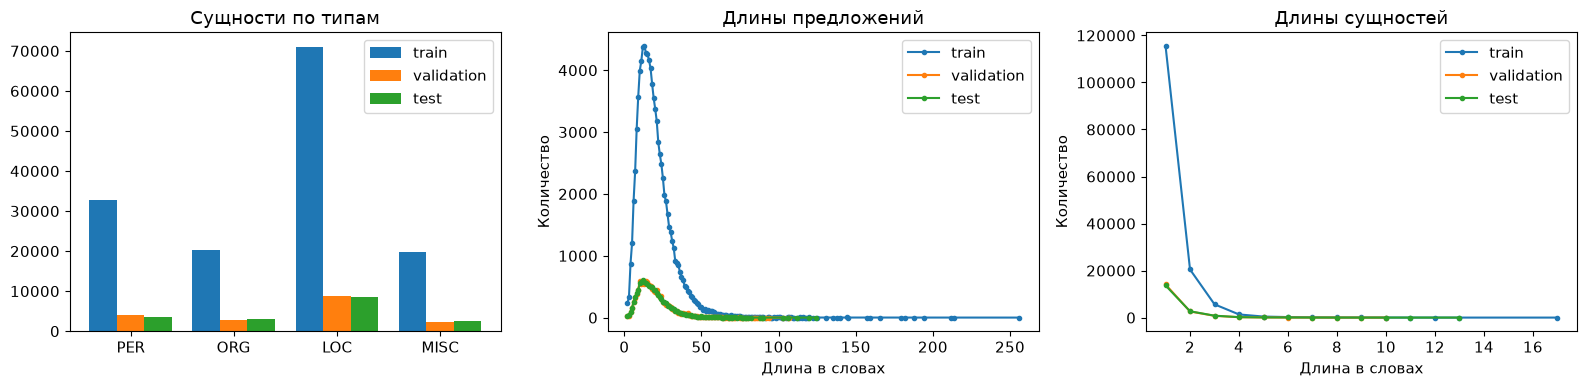

In [15]:
entity_types = [t for t in types if t != 'O']
splits = list(result)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

x = np.arange(len(entity_types))
width = 0.8 / len(splits)

for i, split in enumerate(splits):
    counts = result[split]['type_count']
    axes[0].bar(
        x + i * width,
        [counts.get(t, 0) for t in entity_types],
        width,
        label=split
    )

axes[0].set_xticks(x + width * (len(splits) - 1) / 2)
axes[0].set_xticklabels(entity_types)
axes[0].set_title('Сущности по типам')
axes[0].legend()

for split in splits:
    for ax, key, title in [
        (axes[1], 'sentence_lengths', 'Длины предложений'),
        (axes[2], 'span_lengths', 'Длины сущностей'),
    ]:
        distribution = result[split][key]
        ax.plot(
            list(distribution.keys()),
            list(distribution.values()),
            marker='.',
            label=split
        )
        ax.set_title(title)
        ax.set_xlabel('Длина в словах')
        ax.set_ylabel('Количество')
        ax.legend()

plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** WikiNEuRal RU содержит русские тексты из Википедии. Разметку BIO создали автоматически: в пайплайне Babelscape сочетались база знаний BabelNet и нейросетевые модели. Лицензия датасета — CC BY-NC-SA 4.0. В разметке четыре типа сущностей: PER, ORG, LOC и MISC.

На графике LOC заметно преобладает во всех сплитах. В train около 33 тыс. PER, 20 тыс. ORG, 71 тыс. LOC и 20 тыс. MISC; в validation и test сущностей меньше, но соотношение типов похоже. Чаще всего спаны состоят из одного слова; с увеличением длины их количество быстро уменьшается. Большинство предложений короче 50 слов, хотя встречаются предложения длиной более 200 слов.

Дисбаланс типов может ухудшить распознавание ORG и MISC. Длинные предложения могут обрезаться при токенизации. Поскольку разметка автоматическая, возможны ошибки в границах и типах сущностей.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [17]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans = []

    current_span_start = 0
    current_span_length = 0
    current_span_tag = ''

    for i in range(len(tags)):
        if tags[i] != 'O':
            tag_prefix, tag_body = tags[i].split('-', 1)
            if tag_body == current_span_tag and tag_prefix == 'I':
                current_span_length += 1
            else:
                if current_span_length > 0:
                    spans.append((current_span_start, current_span_start + current_span_length, current_span_tag))
                current_span_start = i
                current_span_length = 1
                current_span_tag = tag_body
        else:
            if current_span_length > 0:
                spans.append((current_span_start, current_span_start + current_span_length, current_span_tag))
                current_span_length = 0
                current_span_tag = ''

    if current_span_length > 0:
        spans.append((current_span_start, current_span_start + current_span_length, current_span_tag))

    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    bio = []
    i = 0
    for span in spans:
        begin, end, tag_body = span
        while i < begin:
            bio.append('O')
            i += 1
        bio.append(f'B-{tag_body}')
        i += 1
        while i < end:
            bio.append(f'I-{tag_body}')
            i += 1
    for _ in range(i, n_words):
        bio.append('O')
    return bio



def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    aligned = []
    seen_word_ids = set()

    for word_id in word_ids:
        if word_id is None:
            aligned.append(-100)
            continue

        label_id = word_labels[word_id]

        if word_id not in seen_word_ids:
            aligned.append(label_id)
            seen_word_ids.add(word_id)
        elif b_to_i is None:
            aligned.append(-100)
        else:
            aligned.append(b_to_i.get(label_id, label_id))

    return aligned

In [18]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [19]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
data_dir = Path('data')
data_dir.mkdir(parents=True, exist_ok=True)

for split in ('train', 'validation', 'test'):
    file_path = data_dir / f'{split}_spans.jsonl'

    with file_path.open('w', encoding='utf-8') as file:
        for example in raw[split]:
            tags = [LABEL_NAMES[tag_id] for tag_id in example['ner_tags']]
            record = {
                'tokens': example['tokens'],
                'spans': bio_to_spans(tags),
            }
            file.write(json.dumps(record, ensure_ascii=False) + '\n')

    mismatch_sentences = 0
    mismatch_tags = 0

    with file_path.open('r', encoding='utf-8') as file:
        for example, line in zip(raw[split], file):
            record = json.loads(line)

            assert record['tokens'] == example['tokens']

            original_tags = [
                LABEL_NAMES[tag_id] for tag_id in example['ner_tags']
            ]
            restored_tags = spans_to_bio(
                record['spans'],
                len(record['tokens']),
            )

            changed = sum(
                original != restored
                for original, restored in zip(original_tags, restored_tags)
            )
            mismatch_tags += changed
            mismatch_sentences += changed > 0

    print(
        f'{split}: {len(raw[split])} примеров, '
        f'{mismatch_sentences} примеров с расхождениями, '
        f'{mismatch_tags} изменённых тегов; файл: {file_path}'
    )

train: 92320 примеров, 3210 примеров с расхождениями, 4325 изменённых тегов; файл: data\train_spans.jsonl
validation: 11540 примеров, 393 примеров с расхождениями, 505 изменённых тегов; файл: data\validation_spans.jsonl
test: 11580 примеров, 464 примеров с расхождениями, 604 изменённых тегов; файл: data\test_spans.jsonl


In [20]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map: 100%|██████████| 11580/11580 [00:00<00:00, 18652.63 examples/s]


DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 92320
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11580
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']
train: проверено 92236 предложений, обрезано по MAX_LENGTH 83, слов без сабвордов или за обрезкой 2196
[CLS]            None  -100
Детство             0  O
провёл              1  O
в                   2  O
Над                 3  B-LOC
##ь                 3  -100
##сом               3  -100
##бат               3  -100
##е                 3  -100
,                   4  O
с                   5  O
1860                6  O
г                   7  O
.                   8  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** метка ставится только первому сабворду, чтобы длинное слово не получало больший вес в loss; `-100` исключает остальные сабворды и специальные токены из `CrossEntropyLoss`. Предсказание для слова также берется с первого сабворда.

На полном train проверены 92 320 предложений: метки восстановлены и спаны сопоставлены для 92 236 предложений без потерянных слов. Длины 83 токенизированных последовательностей достигли `MAX_LENGTH=128`; у 84 предложений обнаружены слова без сабворда или за границей обрезки, всего 2196 слов. Равенство длины 128 само по себе не доказывает обрезку. Проверка выравнивания в этой ячейке не охватывает validation и test.

При преобразовании BIO → спаны → BIO изменились 4325 тегов в 3210 предложениях train, 505 в 393 validation и 604 в 464 test. Причина — исходные `I-X`, не продолжающие сущность того же типа: обратное преобразование начинает новый спан с `B-X`.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [21]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [22]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    frequencies = dict()
    for i in range(len(tokens_list)):
        sentence = tokens_list[i]
        for j in range(len(sentence)):
            word = sentence[j]
            tag = tags_list[i][j]
            if word not in frequencies.keys():
                frequencies[word] = dict()
                frequencies[word][tag] = 1
            elif tag not in frequencies[word].keys():
                frequencies[word][tag] = 1
            else:
                frequencies[word][tag] += 1

    result = dict()
    for word in frequencies.keys():
        result[word] = max(frequencies[word], key=frequencies[word].get)

    return result


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    result = []
    for word in words:
        if word not in tagger.keys():
            result.append('O')
        else:
            result.append(tagger[word])
    return result

In [23]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}
train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [
    [LABEL_NAMES[i] for i in tags]
    for tags in data['train']['ner_tags']
]

tagger = fit_majority_tagger(train_tokens, train_tags)
majority_pred = [predict_majority(tagger, ws) for ws in val_tokens]
baseline['majority'] = entity_scores(val_gold, majority_pred)

random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline['random_head'] = entity_scores(val_gold, random_pred)

Loading weights: 100%|██████████| 53/53 [00:00<?, ?it/s]


In [24]:
import pandas as pd

baseline_df = pd.DataFrame(baseline).T

baseline_df = baseline_df.rename(
    index={
        'majority': 'Словарный бейзлайн',
        'random_head': 'Случайная голова',
    },
    columns={
        'precision': 'Precision',
        'recall': 'Recall',
        'f1_micro': 'Micro-F1',
        'f1_macro': 'Macro-F1',
    },
)

display(
    baseline_df[['Precision', 'Recall', 'Micro-F1', 'Macro-F1']]
    .style
    .format('{:.4f}')
    .set_caption('Метрики на validation')
)

,Precision,Recall,Micro-F1,Macro-F1
Словарный бейзлайн,0.6451,0.5341,0.5844,0.5089
Случайная голова,0.0201,0.1826,0.0363,0.0316


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** на полной validation словарный бейзлайн получил micro-F1 0.5844 и macro-F1 0.5089; precision 0.6451 выше recall 0.5341. Он запоминает наиболее частый тег слова в train и распознаёт часть знакомых сущностей, но не учитывает контекст и пропускает незнакомые слова. Предобученный энкодер со случайной классификационной головой получил micro-F1 0.0363 и macro-F1 0.0316, так как голова еще не обучена предсказывать BIO-теги.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [25]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer

    if freeze_encoder:
        for name, param in model.named_parameters():
            param.requires_grad = name.startswith('classifier.')
        if not any(param.requires_grad for param in model.parameters()):
            raise ValueError('Не найдены обучаемые параметры классификационной головы classifier.')

    data_collator = DataCollatorForTokenClassification(
        tokenizer=tok,
        label_pad_token_id=-100,
    )

    steps_per_epoch = math.ceil(len(train_ds) / batch_size)
    total_steps = math.ceil(steps_per_epoch * epochs)
    eval_steps = max(1, total_steps // 10)

    training_args = TrainingArguments(
        output_dir=out_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        num_train_epochs=epochs,
        eval_strategy='steps',
        eval_steps=eval_steps,
        logging_strategy='steps',
        logging_steps=eval_steps,
        logging_first_step=True,
        warmup_steps=int(total_steps * 0.1),
        weight_decay=0.01,
        fp16=(device.type == 'cuda'),
        seed=SEED,
        save_strategy='no',
        report_to='none',
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        data_collator=data_collator,
        processing_class=tok,
    )

    start_time = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start_time
    history = [dict(item) for item in trainer.state.log_history]

    return history, seconds

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 7629.67it/s]


{'loss': '2.095', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.0003466'}
{'loss': '0.2865', 'grad_norm': '0.6789', 'learning_rate': '0.0001998', 'epoch': '0.2998'}
{'eval_loss': '0.08298', 'eval_runtime': '3.361', 'eval_samples_per_second': '3433', 'eval_steps_per_second': '107.4', 'epoch': '0.2998'}
{'loss': '0.08067', 'grad_norm': '1.142', 'learning_rate': '0.0001778', 'epoch': '0.5997'}
{'eval_loss': '0.06969', 'eval_runtime': '3.476', 'eval_samples_per_second': '3320', 'eval_steps_per_second': '103.9', 'epoch': '0.5997'}
{'loss': '0.07026', 'grad_norm': '0.674', 'learning_rate': '0.0001556', 'epoch': '0.8995'}
{'eval_loss': '0.06415', 'eval_runtime': '3.453', 'eval_samples_per_second': '3343', 'eval_steps_per_second': '104.6', 'epoch': '0.8995'}
{'loss': '0.04996', 'grad_norm': '0.5504', 'learning_rate': '0.0001334', 'epoch': '1.199'}
{'eval_loss': '0.06486', 'eval_runtime': '3.405', 'eval_samples_per_second': '3389', 'eval_steps_per_second': '106', 'epoch': '1.199'}
{'los

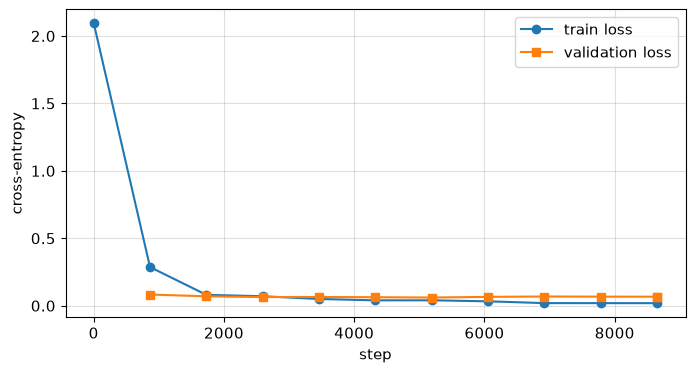

In [26]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** для компактной `rubert-tiny2` выбран learning rate 2e-4 как стартовое значение для дообучения. Batch size 32 даёт компромисс между скоростью и расходом памяти. Три эпохи выбраны по условию в начале файла. Warmup на 10% шагов плавно увеличивает learning rate в начале обучения, weight decay 0.01 служит регуляризацией, а fp16 на GPU снижает расход видеопамяти и ускоряет вычисления.

Обучение на 92 320 предложениях за три эпохи заняло 308.3 с. Train loss снижался, а validation loss после минимума около 0.0607 к 1.8-й эпохе вырос до 0.0667 к концу третьей: это слабый признак переобучения, поэтому по этим кривым нет оснований добавлять эпохи. Для выбора лучшей эпохи полезно также сравнить validation F1 на контрольных точках.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [27]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = fp = fn = 0

    for gold_sentence, pred_sentence in zip(gold, pred):
        for gold_tag, pred_tag in zip(gold_sentence, pred_sentence):
            if gold_tag == pred_tag and gold_tag != 'O':
                tp += 1
            else:
                if pred_tag != 'O':
                    fp += 1
                if gold_tag != 'O':
                    fn += 1

    denominator = 2 * tp + fp + fn
    return 2 * tp / denominator if denominator else 0.0

In [28]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

val_pred = predict_word_tags(model, val_tokens)
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)

val_scores = entity_scores(val_gold, val_pred)
test_scores = entity_scores(test_gold, test_pred)
val_token_score = token_f1(val_gold, val_pred)
test_token_score = token_f1(test_gold, test_pred)

print('Validation report')
print(classification_report(val_gold, val_pred, digits=4, zero_division=0))
print(f"Validation: micro-F1={val_scores['f1_micro']:.4f}, macro-F1={val_scores['f1_macro']:.4f}, token-F1={val_token_score:.4f}")

print('Test report')
print(classification_report(test_gold, test_pred, digits=4, zero_division=0))
print(f"Test: micro-F1={test_scores['f1_micro']:.4f}, macro-F1={test_scores['f1_macro']:.4f}, token-F1={test_token_score:.4f}")

test_report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
per_type = {entity_type: test_report[entity_type] for entity_type in ENTITY_TYPES if entity_type in test_report}

final = {
    'f1_micro': test_scores['f1_micro'],
    'f1_macro': test_scores['f1_macro'],
    'precision': test_scores['precision'],
    'recall': test_scores['recall'],
    'token_f1': test_token_score,
    'per_type': per_type,
}

Validation report
              precision    recall  f1-score   support

         LOC     0.9096    0.9217    0.9156      8851
        MISC     0.7308    0.7400    0.7354      2642
         ORG     0.7558    0.7937    0.7743      2710
         PER     0.8616    0.8792    0.8703      4007

   micro avg     0.8497    0.8669    0.8582     18210
   macro avg     0.8144    0.8337    0.8239     18210
weighted avg     0.8502    0.8669    0.8585     18210

Validation: micro-F1=0.8582, macro-F1=0.8239, token-F1=0.8704
Test report
              precision    recall  f1-score   support

         LOC     0.9181    0.9264    0.9222      8596
        MISC     0.7522    0.7593    0.7557      2962
         ORG     0.7486    0.7886    0.7681      3051
         PER     0.8620    0.8971    0.8792      3489

   micro avg     0.8509    0.8702    0.8604     18098
   macro avg     0.8202    0.8428    0.8313     18098
weighted avg     0.8516    0.8702    0.8607     18098

Test: micro-F1=0.8604, macro-F1=0.8313

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** хуже всего распознается MISC (F1 0.7557), затем ORG (0.7681); лучше всего — LOC (0.9222). В test для LOC размечено 8596 спанов, для MISC — 2962, для ORG — 3051. Вероятно, одни типы распознаются хуже других из-за более низкой частоты. Micro-F1 0.8604 выше macro-F1 0.8313: первый учитывает суммарное число сущностей, второй даёт каждому типу равный вес. Token-F1 0.8750 немного выше F1 по целым сущностям 0.8604; совпадение отдельных слов не требует точного совпадения всего спана. Для NER важнее F1 по сущностям, учитывающий тип и границы.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [29]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    def intersects(a, b):
        return max(a[0], b[0]) < min(a[1], b[1])

    result = []
    for gold_span in gold_spans:
        category = ERROR_CATEGORIES[3]
        pred = None
        for pred_span in pred_spans:
            if gold_span == pred_span:
                category = ERROR_CATEGORIES[0]
                pred = pred_span
                break
            elif intersects(gold_span, pred_span):
                if gold_span[2] == pred_span[2]:
                    category = ERROR_CATEGORIES[1]
                    pred = pred_span
                else:
                    if ERROR_CATEGORIES.index(category) > 2:
                        category = ERROR_CATEGORIES[2]
                        pred = pred_span
        result.append((category, gold_span, pred))

    for pred_span in pred_spans:
        if all(not intersects(pred_span, gold_span) for gold_span in gold_spans):
            result.append((ERROR_CATEGORIES[-1], None, pred_span))

    return result

In [30]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

def tags_to_spans(tags):
    spans = []
    start = None
    entity_type = None

    for i, tag in enumerate(tags):
        if tag == 'O':
            if start is not None:
                spans.append((start, i, entity_type))
                start = None
                entity_type = None
            continue

        prefix, current_type = tag.split('-', 1)

        if prefix == 'B' or start is None or current_type != entity_type:
            if start is not None:
                spans.append((start, i, entity_type))
            start = i
            entity_type = current_type

    if start is not None:
        spans.append((start, len(tags), entity_type))

    return spans


error_counts = collections.Counter()
examples_by_category = {
    category: []
    for category in ERROR_CATEGORIES
    if category != 'correct'
}

for tokens, gold_tags, pred_tags in zip(val_tokens, val_gold, val_pred):
    gold_spans = tags_to_spans(gold_tags)
    pred_spans = tags_to_spans(pred_tags)

    for category, gold_span, pred_span in categorize_errors(gold_spans, pred_spans):
        error_counts[category] += 1

        if category != 'correct' and len(examples_by_category[category]) < 5:
            examples_by_category[category].append(
                (tokens, gold_span, pred_span)
            )

errors = {
    category: error_counts.get(category, 0)
    for category in ERROR_CATEGORIES
}

total_errors = sum(
    errors[category]
    for category in ERROR_CATEGORIES
    if category != 'correct'
)

error_shares = {
    category: (
        errors[category] / total_errors
        if total_errors
        else 0.0
    )
    for category in ERROR_CATEGORIES
    if category != 'correct'
}

print('Количество по категориям:', errors)
print('Доли среди ошибок:')
for category, share in error_shares.items():
    print(f'{category}: {share:.1%}')


def format_span(tokens, span):
    if span is None:
        return None

    start, end, entity_type = span
    text = ' '.join(tokens[start:end])
    return f"{entity_type} '{text}' [{start}:{end}]"


selected_examples = []

for category in examples_by_category:
    if examples_by_category[category]:
        tokens, gold_span, pred_span = examples_by_category[category][0]
        selected_examples.append((category, tokens, gold_span, pred_span))

for index in range(1, 5):
    for category in examples_by_category:
        if len(selected_examples) >= 5:
            break

        if len(examples_by_category[category]) > index:
            tokens, gold_span, pred_span = examples_by_category[category][index]
            selected_examples.append((category, tokens, gold_span, pred_span))

    if len(selected_examples) >= 5:
        break

print('Примеры ошибок:')
for i, (category, tokens, gold_span, pred_span) in enumerate(selected_examples, 1):
    print(f'{i}. {category}')
    print('   Предложение:', ' '.join(tokens))
    print('   Gold:', format_span(tokens, gold_span))
    print('   Pred:', format_span(tokens, pred_span))

Количество по категориям: {'correct': 15787, 'boundary': 681, 'type': 1364, 'missed': 378, 'spurious': 586}
Доли среди ошибок:
boundary: 22.6%
type: 45.3%
missed: 12.6%
spurious: 19.5%
Примеры ошибок:
1. boundary
   Предложение: Позднее , в 2001 г. , он вновь возьмётся за театральную роль в хите лондонского Вест-Энда " « Кошка на раскалённой крыше » " Теннесси Уильямса .
   Gold: MISC 'Кошка на раскалённой крыше »' [18:23]
   Pred: MISC 'Кошка' [18:19]
2. type
   Предложение: В 26 лет Ларго наследует огромную корпорацию и миллиардное состояние .
   Gold: PER 'Ларго' [3:4]
   Pred: LOC 'Ларго' [3:4]
3. missed
   Предложение: Течёт с северо-запада на юго-восток в пределах территории Украины и Молдавии , в том числе по территории , подконтрольной непризнанной ПМР .
   Gold: LOC 'ПМР' [20:21]
   Pred: None
4. spurious
   Предложение: С 1979 года на Украине лесосплав на реках запрещен , что закреплено в Водном кодексе Украины ( 1995 ) , ст .
   Gold: None
   Pred: MISC 'Водном кодексе' [13:

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** на validation обнаружено 3009 ошибок. Чаще всего встречается `type` — 1364 (45.3%); далее `boundary` — 681 (22.6%), `spurious` — 586 (19.5%) и `missed` — 378 (12.6%). При `type` предсказание пересекает истинный спан, но имеет другой тип: например, `Ларго` (PER) предсказано как LOC. При `boundary` найдена только часть сущности: `Кошка` вместо `Кошка на раскалённой крыше »` и `Уильямса` вместо `Теннесси Уильямса`. Модель пропустила `ПМР` (LOC), а `Водном кодексе` предсказала как MISC при отсутствии такого спана в gold.

Для уменьшения ошибок `type` сначала следует изучить пары путаемых типов и конкретные контексты, затем проверить спорную разметку и добавить соответствующие примеры в обучение.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [31]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'

full_scores = entity_scores(val_gold, val_pred)
full_token_score = token_f1(val_gold, val_pred)
full_trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

set_seed(SEED)
frozen_model = make_model()

frozen_history, frozen_seconds = train_ner(
    frozen_model,
    tokenized['train'],
    tokenized['validation'],
    freeze_encoder=True,
    out_dir='runs/freeze',
)

frozen_pred = predict_word_tags(frozen_model, val_tokens)
frozen_scores = entity_scores(val_gold, frozen_pred)
frozen_token_score = token_f1(val_gold, frozen_pred)
frozen_trainable_params = sum(
    param.numel()
    for param in frozen_model.parameters()
    if param.requires_grad
)

ablation = {
    'setting': 'freeze',
    'full_finetuning': {
        **full_scores,
        'token_f1': full_token_score,
        'seconds': float(train_seconds),
        'trainable_params': int(full_trainable_params),
    },
    'frozen_encoder': {
        **frozen_scores,
        'token_f1': frozen_token_score,
        'seconds': float(frozen_seconds),
        'trainable_params': int(frozen_trainable_params),
    },
}

rows = [
    ('Полное дообучение', ablation['full_finetuning']),
    ('Энкодер заморожен', ablation['frozen_encoder']),
]

print(
    f"{'Вариант':<24}"
    f"{'Micro-F1':>11}"
    f"{'Macro-F1':>11}"
    f"{'Token-F1':>11}"
    f"{'Время, с':>12}"
    f"{'Обучаемых параметров':>24}"
)
print('-' * 93)

for name, scores in rows:
    print(
        f"{name:<24}"
        f"{scores['f1_micro']:>11.4f}"
        f"{scores['f1_macro']:>11.4f}"
        f"{scores['token_f1']:>11.4f}"
        f"{scores['seconds']:>12.2f}"
        f"{scores['trainable_params']:>24}"
    )

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 7535.02it/s]


{'loss': '2.095', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.0003466'}
{'loss': '0.8954', 'grad_norm': '0.2896', 'learning_rate': '0.0001998', 'epoch': '0.2998'}
{'eval_loss': '0.2725', 'eval_runtime': '3.562', 'eval_samples_per_second': '3240', 'eval_steps_per_second': '101.3', 'epoch': '0.2998'}
{'loss': '0.2341', 'grad_norm': '0.2413', 'learning_rate': '0.0001778', 'epoch': '0.5997'}
{'eval_loss': '0.1913', 'eval_runtime': '3.493', 'eval_samples_per_second': '3304', 'eval_steps_per_second': '103.3', 'epoch': '0.5997'}
{'loss': '0.197', 'grad_norm': '0.2472', 'learning_rate': '0.0001556', 'epoch': '0.8995'}
{'eval_loss': '0.1703', 'eval_runtime': '3.565', 'eval_samples_per_second': '3237', 'eval_steps_per_second': '101.3', 'epoch': '0.8995'}
{'loss': '0.1823', 'grad_norm': '0.2243', 'learning_rate': '0.0001334', 'epoch': '1.199'}
{'eval_loss': '0.1611', 'eval_runtime': '3.486', 'eval_samples_per_second': '3311', 'eval_steps_per_second': '103.6', 'epoch': '1.199'}
{'loss': 

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** заморозка энкодера снизила micro-F1 с 0.8582 до 0.6324 (на 0.2259), а macro-F1 — с 0.8239 до 0.5376. Время обучения сократилось с 308.27 до 162.06 с; число обучаемых параметров — с 29 098 929 до 2817. Голова использует предобученные признаки, но полное дообучение в этом эксперименте даёт лучшее качество. Для надежности результата сравнение стоит повторить при нескольких seed и оценить разброс F1.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** после трех эпох на 92 320 предложениях `rubert-tiny2` получила micro-F1 0.8582 на validation и 0.8604 на test. Словарный бейзлайн достиг 0.5844 на validation. На test лучше всего распознаётся LOC (F1 0.9222), хуже всего — MISC (0.7557). На полной validation наиболее часты ошибки типа: 1364 из 3009 (45.3%). Заморозка энкодера снизила validation micro-F1 с 0.8582 до 0.6324. Ограничения эксперимента — автоматическая разметка WikiNEuRal, различия в частоте типов и один seed. Дальше стоит разобрать частые путаницы типов и проверить спорные аннотации перед повторением обучения.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [32]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 92320, "n_val": 11540, "n_test": 11580, "params_total": 29098929, "ablation": {"setting": "freeze", "full_finetuning": {"f1_micro": 0.858245671260431, "f1_macro": 0.8238954803863173, "precision": 0.849722805317832, "recall": 0.8669412410763316, "token_f1": 0.8703538074339081, "seconds": 308.2749365000009, "trainable_params": 29098929}, "frozen_encoder": {"f1_micro": 0.6323922419495673, "f1_macro":
final F1 micro 0.8604


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [33]:
if '6.1' in BONUS_TASKS:
    # Файл формата data/<name>_spans.jsonl: токены и спаны [start, end, type], end не включается.
    manual_path = Path('data/manual_spans.jsonl')
    assert manual_path.exists(), f'Не найден файл ручной разметки: {manual_path}'

    manual_records = []
    with manual_path.open(encoding='utf-8') as file:
        for line_number, line in enumerate(file, start=1):
            if not line.strip():
                continue
            record = json.loads(line)
            assert set(record) == {'tokens', 'spans'}, f'Строка {line_number}: ожидаются tokens и spans'
            tokens, spans = record['tokens'], record['spans']
            assert isinstance(tokens, list) and tokens and all(isinstance(w, str) for w in tokens), line_number

            normalized_spans = []
            previous_end = 0
            for start, end, entity_type in spans:
                assert entity_type in ENTITY_TYPES, f'Строка {line_number}: неизвестный тип {entity_type}'
                assert isinstance(start, int) and isinstance(end, int), line_number
                assert 0 <= start < end <= len(tokens), f'Строка {line_number}: границы спана вне предложения'
                assert start >= previous_end, f'Строка {line_number}: спаны пересекаются или не отсортированы'
                normalized_spans.append((start, end, entity_type))
                previous_end = end

            bio_tags = spans_to_bio(normalized_spans, len(tokens))
            assert len(bio_tags) == len(tokens)
            assert bio_to_spans(bio_tags) == normalized_spans, f'Строка {line_number}: BIO round-trip не совпал'
            manual_records.append({'tokens': tokens, 'ner_tags': [label2id[tag] for tag in bio_tags]})

    assert len(manual_records) >= 50, f'Для 6.1 нужно не менее 50 предложений, найдено {len(manual_records)}'
    manual_keys = [tuple(row['tokens']) for row in manual_records]
    assert len(set(manual_keys)) == len(manual_keys), 'В ручной разметке есть повторяющиеся предложения'

    # Подтверждаем источник: эти предложения взяты из validation, и ни одно не попало в test.
    validation_keys = {tuple(row['tokens']) for row in raw['validation']}
    test_keys = {tuple(row['tokens']) for row in raw['test']}
    train_keys = {tuple(row['tokens']) for row in raw['train']}
    assert set(manual_keys) <= validation_keys, 'Некоторые ручные примеры не найдены в исходной validation'
    assert not (set(manual_keys) & test_keys), 'Ручные примеры пересекаются с test — обучать на них нельзя'

    manual_key_set = set(manual_keys)

    # Если предложение уже есть в train, повторно его не добавляем.
    new_records = [row for row in manual_records if tuple(row['tokens']) not in train_keys]
    manual_train_raw = datasets.Dataset.from_list(new_records)
    manual_train_tokenized = manual_train_raw.map(
        tokenize_and_align, batched=True, remove_columns=manual_train_raw.column_names,
    )
    augmented_train = datasets.concatenate_datasets([tokenized['train'], manual_train_tokenized])

    # Так как добавленные примеры взяты из validation, убираем их оттуда.
    clean_validation_raw = data['validation'].filter(
        lambda row: tuple(row['tokens']) not in manual_key_set
    )
    assert len(clean_validation_raw) > 0, 'После исключения ручных примеров validation пуст'
    clean_validation = clean_validation_raw.map(
        tokenize_and_align, batched=True, remove_columns=clean_validation_raw.column_names,
    )

    set_seed(SEED)
    manual_model = make_model()
    manual_history, manual_train_seconds = train_ner(
        manual_model, augmented_train, clean_validation,
        out_dir='runs/bonus_61_manual',
    )
    manual_pred = predict_word_tags(manual_model, test_tokens)
    manual_scores = entity_scores(test_gold, manual_pred)

    manual_type_counts = collections.Counter(
        entity_type
        for row in manual_records
        for _, _, entity_type in bio_to_spans([LABEL_NAMES[i] for i in row['ner_tags']])
    )
    print(f'Ручная разметка: {len(manual_records)} предложений, добавлено в train: {len(new_records)}')
    print('Число размеченных сущностей по типам:', dict(sorted(manual_type_counts.items())))
    print(f'Размер train: {len(tokenized["train"])} -> {len(augmented_train)}; '
          f'clean validation: {len(clean_validation_raw)}; test: {len(test_gold)} (тот же, что до обучения)')
    print(f'Время дообучения модели с разметкой: {manual_train_seconds:.1f} с')
    print(f"Test micro-F1: {test_scores['f1_micro']:.4f} -> {manual_scores['f1_micro']:.4f} "
          f"({manual_scores['f1_micro'] - test_scores['f1_micro']:+.4f})")
    print(f"Test macro-F1: {test_scores['f1_macro']:.4f} -> {manual_scores['f1_macro']:.4f} "
          f"({manual_scores['f1_macro'] - test_scores['f1_macro']:+.4f})")
    print(f"Test precision: {test_scores['precision']:.4f} -> {manual_scores['precision']:.4f}; "
          f"recall: {test_scores['recall']:.4f} -> {manual_scores['recall']:.4f}")



Loading weights: 100%|██████████| 53/53 [00:00<?, ?it/s]


{'loss': '2.122', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.0003464'}
{'loss': '0.2888', 'grad_norm': '0.7189', 'learning_rate': '0.0001998', 'epoch': '0.3'}
{'eval_loss': '0.08638', 'eval_runtime': '3.512', 'eval_samples_per_second': '3269', 'eval_steps_per_second': '102.2', 'epoch': '0.3'}
{'loss': '0.07907', 'grad_norm': '0.4909', 'learning_rate': '0.0001778', 'epoch': '0.5999'}
{'eval_loss': '0.07068', 'eval_runtime': '3.458', 'eval_samples_per_second': '3320', 'eval_steps_per_second': '103.8', 'epoch': '0.5999'}
{'loss': '0.07014', 'grad_norm': '0.5344', 'learning_rate': '0.0001556', 'epoch': '0.8999'}
{'eval_loss': '0.06306', 'eval_runtime': '3.482', 'eval_samples_per_second': '3297', 'eval_steps_per_second': '103.1', 'epoch': '0.8999'}
{'loss': '0.04991', 'grad_norm': '0.8444', 'learning_rate': '0.0001334', 'epoch': '1.2'}
{'eval_loss': '0.06619', 'eval_runtime': '3.462', 'eval_samples_per_second': '3316', 'eval_steps_per_second': '103.7', 'epoch': '1.2'}
{'loss': '0

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

Размечено 60 предложений и 103 сущности: LOC — 33, MISC — 30, PER — 21, ORG — 19. В train добавлены все 60 предложений; поскольку они взяты из validation, их исключили из нее при обучении, а сравнение провели на неизменном test из 11 580 предложений. Test micro-F1 изменился с 0.8604 до 0.8599 (−0.0005), macro-F1 — с 0.8313 до 0.8304 (−0.0009). Улучшения в этом прогоне нет; изменение очень мало и практически не возымело влияния.

На разметку было потрачено около получаса, наиболее сомнительными местами были те, где неясно, какую категорию назначать слову и стоит ли назначать ее вообще (например, «доллар США»).

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [39]:
if '6.2' in BONUS_TASKS:
    alt_id = 'cointegrated/rubert-tiny'
    alt_revision = 'f191937ca7511ae76b44b06a460f18ab1699c54b'

    alt_tokenizer = AutoTokenizer.from_pretrained(
        alt_id,
        revision=alt_revision,
    )
    assert alt_tokenizer.is_fast

    alt_data = data.map(
        tokenize_and_align,
        batched=True,
        fn_kwargs={'tok': alt_tokenizer},
        remove_columns=data['train'].column_names,
    )

    def inference_seconds_per_1000(model_to_time, tok_to_use, tokens, repeats=3):
        sample = tokens[:min(1000, len(tokens))]
        model_to_time.to(device).eval()

        predict_word_tags(
            model_to_time,
            sample,
            tok=tok_to_use,
            batch_size=BATCH_SIZE,
            dev=device,
        )

        times = []
        for _ in range(repeats):
            if device.type == 'cuda':
                torch.cuda.synchronize(device)

            started = time.perf_counter()
            predict_word_tags(
                model_to_time,
                sample,
                tok=tok_to_use,
                batch_size=BATCH_SIZE,
                dev=device,
            )

            if device.type == 'cuda':
                torch.cuda.synchronize(device)

            times.append(time.perf_counter() - started)

        return float(np.mean(times)) * 1000 / len(sample)

    main_infer = inference_seconds_per_1000(model, tokenizer, test_tokens)
    main_params = sum(p.numel() for p in model.parameters())
    main_mib = sum(
        p.numel() * p.element_size()
        for p in model.parameters()
    ) / 2**20

    model.to('cpu')
    if device.type == 'cuda':
        torch.cuda.empty_cache()

    set_seed(SEED)
    alt_model = make_model(alt_id, alt_revision)

    _, alt_train_seconds = train_ner(
        alt_model,
        alt_data['train'],
        alt_data['validation'],
        lr=LR,
        batch_size=BATCH_SIZE,
        tok=alt_tokenizer,
        out_dir='runs/model_62_rubert_tiny',
    )

    alt_pred = predict_word_tags(
        alt_model,
        test_tokens,
        tok=alt_tokenizer,
        batch_size=BATCH_SIZE,
        dev=device,
    )
    alt_scores = entity_scores(test_gold, alt_pred)
    alt_infer = inference_seconds_per_1000(
        alt_model,
        alt_tokenizer,
        test_tokens,
    )
    alt_params = sum(p.numel() for p in alt_model.parameters())
    alt_mib = sum(
        p.numel() * p.element_size()
        for p in alt_model.parameters()
    ) / 2**20

    print(
        f"{'Модель':<38}"
        f"{'micro-F1':>10}"
        f"{'train, с':>12}"
        f"{'infer, с/1000':>16}"
        f"{'params':>14}"
        f"{'weights, MiB':>15}"
    )
    print(
        f"{MODEL_ID:<38}"
        f"{test_scores['f1_micro']:>10.4f}"
        f"{train_seconds:>12.1f}"
        f"{main_infer:>16.3f}"
        f"{main_params:>14,}"
        f"{main_mib:>15.1f}"
    )
    print(
        f"{alt_id:<38}"
        f"{alt_scores['f1_micro']:>10.4f}"
        f"{alt_train_seconds:>12.1f}"
        f"{alt_infer:>16.3f}"
        f"{alt_params:>14,}"
        f"{alt_mib:>15.1f}"
    )

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 32797.01it/s]


{'loss': '2.129', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.0003466'}
{'loss': '0.3063', 'grad_norm': '1.211', 'learning_rate': '0.0001998', 'epoch': '0.2998'}
{'eval_loss': '0.09269', 'eval_runtime': '4.097', 'eval_samples_per_second': '2817', 'eval_steps_per_second': '88.12', 'epoch': '0.2998'}
{'loss': '0.08966', 'grad_norm': '1.104', 'learning_rate': '0.0001778', 'epoch': '0.5997'}
{'eval_loss': '0.07702', 'eval_runtime': '4.089', 'eval_samples_per_second': '2822', 'eval_steps_per_second': '88.28', 'epoch': '0.5997'}
{'loss': '0.07832', 'grad_norm': '0.6322', 'learning_rate': '0.0001556', 'epoch': '0.8995'}
{'eval_loss': '0.06996', 'eval_runtime': '4.18', 'eval_samples_per_second': '2761', 'eval_steps_per_second': '86.36', 'epoch': '0.8995'}
{'loss': '0.06118', 'grad_norm': '0.5809', 'learning_rate': '0.0001334', 'epoch': '1.199'}
{'eval_loss': '0.06846', 'eval_runtime': '4.154', 'eval_samples_per_second': '2778', 'eval_steps_per_second': '86.91', 'epoch': '1.199'}
{'lo

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** на одном и том же test `rubert-tiny2` получила micro-F1 0.8604, `rubert-tiny` — 0.8457. Вторая модель меньше: 11.69 против 29.10 млн параметров, 44.6 против 111.0 MiB весов. В этом замере она обучалась немного дольше (320.7 против 308.3 с) и медленнее выполняла инференс (0.723 против 0.549 с на 1000 предложений); меньший размер не обеспечил ускорения на данном устройстве. Использованы одинаковые train, test, число эпох, batch size, learning rate и seed, а скорость инференса измерена на одном устройстве после прогрева.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [35]:
if '6.3' in BONUS_TASKS:
    rng = random.Random(SEED)
    original_f1 = entity_scores(val_gold, val_pred)['f1_micro']

    lower_tokens = [[word.lower() for word in sent] for sent in val_tokens]
    typo_tokens = []
    for sent in val_tokens:
        noisy_sent = []
        for word in sent:
            if len(word) >= 5 and rng.random() < 0.1:
                pos = rng.randrange(1, len(word))
                word = word[:pos] + word[pos + 1:]
            noisy_sent.append(word)
        typo_tokens.append(noisy_sent)

    print(f'Исходный validation micro-F1: {original_f1:.4f}')
    for name, noisy_tokens in [('нижний регистр', lower_tokens), ('опечатки (удаление буквы в 10% слов)', typo_tokens)]:
        noisy_pred = predict_word_tags(model, noisy_tokens)
        noisy_f1 = entity_scores(val_gold, noisy_pred)['f1_micro']
        print(f'{name}: micro-F1={noisy_f1:.4f}, изменение={noisy_f1 - original_f1:+.4f}')

Исходный validation micro-F1: 0.8582
нижний регистр: micro-F1=0.1912, изменение=-0.6671
опечатки (удаление буквы в 10% слов): micro-F1=0.8478, изменение=-0.0104


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** сильнее всего повлиял перевод текста в нижний регистр: validation micro-F1 снизился с 0.8582 до 0.1912 (−0.6671). Удаление буквы в 10% слов длиной не менее пяти символов снизило F1 до 0.8478 (−0.0104). Возможные причины первого падения — потеря признака заглавной буквы у имен и изменение разбиения слов токенизатором.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [ ]:
if '6.4' in BONUS_TASKS:
    cpu = torch.device('cpu')
    bench_tokens = test_tokens[:min(256, len(test_tokens))]

    fp_model = copy.deepcopy(model).to(cpu).eval()
    int8_model = torch.ao.quantization.quantize_dynamic(
        fp_model, {torch.nn.Linear}, dtype=torch.qint8
    ).eval()

    fp_pred = predict_word_tags(fp_model, test_tokens, tok=tokenizer,
                                batch_size=BATCH_SIZE, dev=cpu)
    int8_pred = predict_word_tags(int8_model, test_tokens, tok=tokenizer,
                                  batch_size=BATCH_SIZE, dev=cpu)
    fp_f1 = entity_scores(test_gold, fp_pred)['f1_micro']
    int8_f1 = entity_scores(test_gold, int8_pred)['f1_micro']

    def mean_inference_time(model_to_time, repeats=10):
        predict_word_tags(model_to_time, bench_tokens, tok=tokenizer,
                          batch_size=BATCH_SIZE, dev=cpu)  # прогрев
        times = []
        for _ in range(repeats):
            started = time.perf_counter()
            predict_word_tags(model_to_time, bench_tokens, tok=tokenizer,
                              batch_size=BATCH_SIZE, dev=cpu)
            times.append(time.perf_counter() - started)
        return float(np.mean(times))

    fp_seconds = mean_inference_time(fp_model)
    int8_seconds = mean_inference_time(int8_model)
    print(f'Устройство: CPU; F1 на {len(test_tokens)} test-примерах; замер на {len(bench_tokens)} предложениях')
    print(f'FP32: micro-F1={fp_f1:.4f}, среднее время={fp_seconds:.3f} с')
    print(f'INT8: micro-F1={int8_f1:.4f}, среднее время={int8_seconds:.3f} с')
    print(f'Изменение F1: {int8_f1 - fp_f1:+.4f}; ускорение: {fp_seconds / int8_seconds:.2f}x (10 прогонов + прогрев)')

C:\Users\user\AppData\Local\Temp\ipykernel_29168\3350807436.py:6: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_model = torch.ao.quantization.quantize_dynamic(


Устройство: CPU; F1 на 11580 test-примерах; замер на 256 предложениях
FP32: micro-F1=0.8604, среднее время=0.468 с
INT8: micro-F1=0.8606, среднее время=0.381 с
Изменение F1: +0.0002; ускорение: 1.23x (10 прогонов + прогрев)


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** на CPU динамическая INT8-квантизация линейных слоев ускорила инференс на 256 предложениях с 0.468 до 0.381 с в среднем за прогон (1.23 раза). Micro-F1 на всем test изменился с 0.8604 до 0.8606 (+0.0002), то есть практически не изменился. У `rubert-tiny2` большинство параметров находится в эмбеддингах, которые эта квантизация линейных слоев не затрагивает; выигрыш зависит и от доли вычислений в квантизированных операциях.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

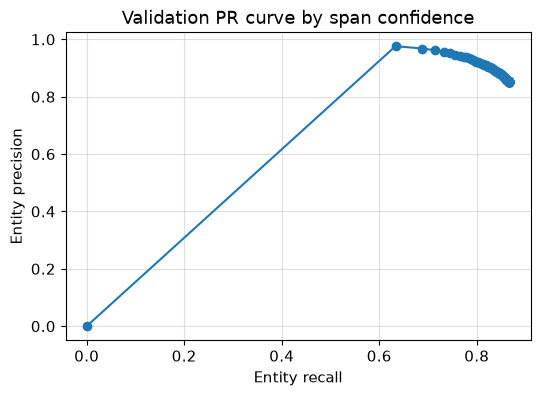

Лучший порог: 0.67
При нулевом пороге: precision=0.8497, recall=0.8669, F1=0.8582
Лучший F1: precision=0.8842, recall=0.8444, F1=0.8638; изменение F1=+0.0056


In [37]:
if '6.5' in BONUS_TASKS:
    pred_tags, word_probs = predict_word_tags(model, val_tokens, return_probs=True)
    pred_spans = [bio_to_spans(tags) for tags in pred_tags]
    span_conf = [
        [float(np.mean(probs[start:end])) for start, end, _ in spans]
        for spans, probs in zip(pred_spans, word_probs)
    ]

    threshold_results = []
    for threshold in np.linspace(0.0, 1.0, 101):
        filtered = [
            spans_to_bio(
                [span for span, conf in zip(spans, confs) if conf >= threshold], len(tags)
            )
            for spans, confs, tags in zip(pred_spans, span_conf, pred_tags)
        ]
        scores = entity_scores(val_gold, filtered)
        threshold_results.append({
            'threshold': float(threshold),
            'precision': scores['precision'],
            'recall': scores['recall'],
            'f1': scores['f1_micro'],
        })

    best_threshold = max(threshold_results, key=lambda row: row['f1'])
    pr_points = sorted(threshold_results, key=lambda row: row['recall'])
    plt.figure(figsize=(6, 4))
    plt.plot([p['recall'] for p in pr_points], [p['precision'] for p in pr_points], 'o-')
    plt.xlabel('Entity recall')
    plt.ylabel('Entity precision')
    plt.title('Validation PR curve by span confidence')
    plt.grid(True, alpha=0.4)
    plt.show()

    baseline_f1 = threshold_results[0]['f1']
    print(f"Лучший порог: {best_threshold['threshold']:.2f}")
    print(f"При нулевом пороге: precision={threshold_results[0]['precision']:.4f}, "
          f"recall={threshold_results[0]['recall']:.4f}, F1={baseline_f1:.4f}")
    print(f"Лучший F1: precision={best_threshold['precision']:.4f}, "
          f"recall={best_threshold['recall']:.4f}, F1={best_threshold['f1']:.4f}; "
          f"изменение F1={best_threshold['f1'] - baseline_f1:+.4f}")

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** лучший из проверенных порогов — 0.67: micro-F1 вырос с 0.8582 при пороге 0 до 0.8638 (+0.0056). Precision вырос с 0.8497 до 0.8842, recall снизился с 0.8669 до 0.8444. Здесь уверенность спана усредняется по словам; минимум сильнее штрафовал бы спаны с одним неуверенно распознанным словом. Повышение порога только удаляет уже найденные спаны и не может вернуть пропущенные, поэтому recall не увеличится.